# Lab 00: Introduction to NumPy — Sales Data Analysis

Four tasks based on slides 17–20 of the lecture:

1. Simulating sales data
2. Computing monthly averages
3. Performance comparison (Python loop vs. NumPy)
4. Weekly sales aggregation

## Task 1. Simulating Sales Data

We simulate daily unit sales for 4 products over 364 days (52 full weeks).
`np.random.randint(low=10, high=101, ...)` draws integers from 10 to 100 (the upper bound is exclusive).
The seed makes the result reproducible. The result is a 2D array with shape `(days, products)`.

In [1]:
import numpy as np

# Set a seed for reproducibility
np.random.seed(42)

# Parameters
num_days = 364
num_products = 4

# Simulate daily sales units
daily_sales = np.random.randint(
    low=10,
    high=101,
    size=(num_days, num_products)
)

# Display shape and first 5 days
print("Shape:", daily_sales.shape)
print("First 5 days:\n", daily_sales[:5])

Shape: (364, 4)
First 5 days:
 [[61 24 81 70]
 [30 92 96 84]
 [84 97 33 12]
 [31 62 11 97]
 [39 47 11 73]]


**Explanation:** the array has shape `(364, 4)`: each row is a day, each column is a product.
All values lie in the range 10–100. Because of the fixed seed, rerunning the cell gives the same data,
and all later tasks reuse this `daily_sales` array.

In [2]:
# Sanity check of the simulated data
print("dtype:", daily_sales.dtype)
print("min / max:", daily_sales.min(), "/", daily_sales.max())

dtype: int32
min / max: 10 / 100


## Task 2. Computing Monthly Averages

We assume a simplified calendar of 12 months with 30 days each, so 360 days. The simulated data has 364 days,
so we take the first 360 rows. Then we reshape the array to `(months, days_per_month, products)` = `(12, 30, 4)`
and average over the days axis (`axis=1`) to get the average daily sales per product per month.

In [2]:
# 12 months of 30 days -> use the first 360 days of the data
days_used = 12 * 30
monthly_sales = daily_sales[:days_used].reshape(12, 30, 4)

# Average daily sales per product per month
monthly_avg_sales = monthly_sales.mean(axis=1)

print("monthly_sales shape:", monthly_sales.shape)
print("monthly_avg_sales shape:", monthly_avg_sales.shape)
print("Average daily sales per month (rows) and product (columns):")
print(np.round(monthly_avg_sales, 2))

monthly_sales shape: (12, 30, 4)
monthly_avg_sales shape: (12, 4)
Average daily sales per month (rows) and product (columns):
[[57.03 55.37 56.73 54.63]
 [53.2  53.87 50.63 60.47]
 [54.6  57.83 54.2  38.37]
 [51.73 49.37 57.7  51.27]
 [56.53 45.83 58.27 50.17]
 [55.5  53.07 57.1  51.33]
 [60.03 56.63 55.6  46.93]
 [51.27 57.03 47.53 59.57]
 [54.07 44.8  54.   49.4 ]
 [56.83 52.57 54.47 60.9 ]
 [52.17 46.33 61.93 52.5 ]
 [50.07 55.9  58.23 51.27]]


In [4]:
# Check: January, product 0 equals the mean of the first 30 days
assert np.isclose(monthly_avg_sales[0, 0], daily_sales[:30, 0].mean())
print("Best month for each product (0-based):", monthly_avg_sales.argmax(axis=0))

Best month for each product (0-based): [ 6  2 10  9]


**Explanation:** `reshape(12, 30, 4)` works only because `12 * 30 * 4` equals the number of elements
in the first 360 rows. Reshaping the full 364 rows would raise an error. `mean(axis=1)` collapses the
"days" axis, giving a `(12, 4)` table: 12 months by 4 products. The check confirms the first value equals
the plain mean of the first 30 days of product 0.

## Task 3. Performance Comparison

We compute the total sales across all products and days in two ways: with nested Python loops and with
the vectorized `np.sum()`. In Jupyter you can use `%timeit`; here we use the `timeit` module, which gives the same
measurement and also lets us compute the speed-up programmatically.

In [5]:
import timeit

def sum_with_loop(data):
    total = 0
    for row in data:
        for item in row:
            total += item
    return total

# Both approaches must give the same answer
assert sum_with_loop(daily_sales) == np.sum(daily_sales)
print("Total sales:", np.sum(daily_sales))

# Timing (equivalent to %timeit sum_with_loop(daily_sales) / %timeit np.sum(daily_sales))
n = 20
t_loop = min(timeit.repeat(lambda: sum_with_loop(daily_sales), number=n, repeat=5)) / n
t_np = min(timeit.repeat(lambda: np.sum(daily_sales), number=n, repeat=5)) / n

print(f"Python loop : {t_loop * 1e6:10.1f} µs per call")
print(f"np.sum()    : {t_np * 1e6:10.1f} µs per call")
print(f"Speed-up    : {t_loop / t_np:.0f}x faster with NumPy")

Total sales: 78055
Python loop :      251.8 µs per call
np.sum()    :        3.0 µs per call
Speed-up    : 84x faster with NumPy


In [6]:
# Same comparison for a larger array, where the gap grows
big = np.random.randint(10, 101, size=(100_000, 4))

t_loop_big = min(timeit.repeat(lambda: sum_with_loop(big), number=1, repeat=3))
t_np_big = min(timeit.repeat(lambda: np.sum(big), number=20, repeat=3)) / 20
print(f"{big.shape}: loop {t_loop_big * 1e3:.1f} ms, np.sum {t_np_big * 1e3:.3f} ms, "
      f"speed-up {t_loop_big / t_np_big:.0f}x")

(100000, 4): loop 73.3 ms, np.sum 0.152 ms, speed-up 483x


**Explanation:** both methods return the same total, but `np.sum()` is dramatically faster. The Python loop
visits every element one by one with type checks on each step, while `np.sum()` runs a single optimized
C loop over contiguous memory. The exact speed-up depends on the machine, but it is typically tens of times
and grows with the array size. This is why vectorization is essential for data analysis.

## Task 4. Weekly Sales Aggregation

364 days = 52 weeks x 7 days, so the data splits evenly into weeks. We reshape `(364, 4)` into
`(52, 7, 4)` = (weeks, days per week, products) and sum over the days axis (`axis=1`)
to get total weekly sales per product.

In [7]:
# daily_sales shape is (364, 4)
# 364 days = 52 weeks * 7 days

# Reshape into (weeks, days_per_week, products)
weekly_sales_data = daily_sales.reshape(52, 7, 4)

# Sum across 'days' axis to get weekly totals
total_weekly_sales = weekly_sales_data.sum(axis=1)

print("Shape of total_weekly_sales:", total_weekly_sales.shape)
print("Total sales for the first week:")
print(total_weekly_sales[0])

Shape of total_weekly_sales: (52, 4)
Total sales for the first week:
[381 383 372 479]


In [8]:
# Check: week 1 totals equal the sum of the first 7 days; grand total is preserved
assert (total_weekly_sales[0] == daily_sales[:7].sum(axis=0)).all()
assert total_weekly_sales.sum() == daily_sales.sum()
print("Best week for each product (0-based):", total_weekly_sales.argmax(axis=0))

Best week for each product (0-based): [10 51 36  4]


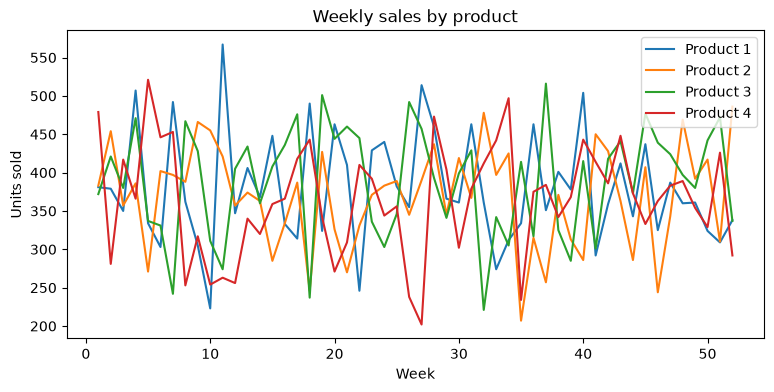

In [9]:
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
for p in range(num_products):
    plt.plot(range(1, 53), total_weekly_sales[:, p], label=f"Product {p + 1}")
plt.xlabel("Week")
plt.ylabel("Units sold")
plt.title("Weekly sales by product")
plt.legend()
plt.show()

**Explanation:** the reshape groups every 7 consecutive days into one week without copying data, and
`sum(axis=1)` adds up the days within each week, producing a `(52, 4)` array. The checks confirm that the first
week equals the sum of the first 7 days and that the grand total is unchanged by the aggregation.

## Conclusion

- `randint` + a seed gives reproducible simulated data.
- `reshape` + `mean`/`sum` along an `axis` turns daily data into monthly or weekly summaries without loops.
- Vectorized NumPy operations are much faster than equivalent Python loops.